In [1]:
%matplotlib widget  
import h5py, os, glob, shutil
import matplotlib.pyplot as plt
import ipympl
import hyperspy.api as hs
import json
import numpy as np
import gc
import subprocess
import py4DSTEM
print(py4DSTEM.__version__)
print(py4DSTEM.__file__)
print(ipympl.__file__)

0.14.19
/dls_sw/apps/python/miniforge/25.11/envs/epsic3.13/lib/python3.13/site-packages/py4DSTEM/__init__.py
/dls_sw/apps/python/miniforge/25.11/envs/epsic3.13/lib/python3.13/site-packages/ipympl/__init__.py


In [2]:
def _make_unique_dir(base_name):
    """Create a directory with an incremented suffix if name exists."""
    if not os.path.exists(base_name):
        os.makedirs(base_name)
        return base_name
    i = 1
    while True:
        candidate = f"{base_name}_{i}"
        if not os.path.exists(candidate):
            os.makedirs(candidate)
            return candidate
        i += 1

working_dir = os.getcwd() # Get current working directory
out_dir = _make_unique_dir(os.path.join(working_dir, 'ptycho_batch')) # Create output in working directory

In [3]:
# def print_attrs(name, obj):
#     print(name)
#     for key, val in obj.attrs.items():
#         print('%s %s' % (key, val))
        
# f = h5py.File(metadata_files[1],'r')
# f.visititems(print_attrs)

In [3]:
# Confirm metadata and find virtual BF images:
root_path = '/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all'
incl_subfolders = True
# all_hdf5_files = glob.glob(root_path + '/*/*.hdf5')
# hdf5_files = sorted(glob.glob(root_path + '/*/*.hdf5'))
if incl_subfolders:
    metadata_files = sorted(glob.glob(root_path + '/*/*/*.hdf'))
    im_files = sorted(glob.glob(root_path + '/*/*/*.jpg'))
else:
    metadata_files = sorted(glob.glob(root_path + '/*/*.hdf'))
    im_files = sorted(glob.glob(root_path + '/*/*.jpg'))
    
print(len(metadata_files))

import ast
def get_upscale_from_cluster(file):
    try:
        a = file['Clusters Found'][()]
        cluster_dict = ast.literal_eval(a.decode('utf-8'))
        c_width = cluster_dict[0]['bbox'][2]- cluster_dict[0]['bbox'][0]
    except Exception as e:
        print(e)
        c_width = 16 # ASSUMED FOR NOW!
        
    if c_width == 8:
        res = 4096 * 2
    else:
        res = 4096
    return res
        
    # f['Clusters Found'][()]


def get_stepsize_from_metadata(file):
    print(file)
    with h5py.File(file,'r') as f: # get metadata from first file
        metadata_fov = f['metadata/field_of_view(m)'][()]
        metadata_res = get_upscale_from_cluster(f)
        step_size = np.round((metadata_fov / metadata_res) * 1e10, 3) #in A
    return step_size

def get_convergence_angle_from_metadata(file):
    """in rads"""
    with h5py.File(file,'r') as f: # get metadata from first file
        metadata_conv_rad = f['metadata/convergence_semi-angle(rad)'][()] 
    return 26.2 *1e-3#metadata_conv_rad

def get_ht_from_metadata(file):
    """in eV"""
    with h5py.File(file,'r') as f:
        ht_ev = f['metadata/ht_value(V)'][()]
    return ht_ev

# with h5py.File(metadata_files[90],'r') as f: # get metadata from first file
#     metadata_mag = f['metadata/magnification'][()]
#     metadata_fov = f['metadata/field_of_view(m)'][()]
#     metadata_ht = f['metadata/ht_value(V)'][()]
#     metadata_cl = f['metadata/nominal_camera_length(m)'][()]

#     metadata_res = get_upscale_from_cluster(f)
#     metadata_conv_rad = f['metadata/convergence_semi-angle(rad)'][()] #* 1e3 #mrad
#     print('file: ' , metadata_files[90])
#     print(metadata_mag)
#     print(metadata_fov)
#     print(metadata_ht)
#     print(metadata_cl)
#     print(metadata_conv_rad)
#     print(metadata_res)

# # Stepsize:
# # Survey image is at 600K - 512
# # Data collected at 4K sampling with 128 * 128 Scan
# # FOV at 600K: 3.3333333333333335e-07m
# step_size = np.round((metadata_fov / metadata_res) * 1e10, 3) #in A
stepsize_check = get_stepsize_from_metadata(metadata_files[0])
print(stepsize_check , "Angstoms") # in A
print(128 * stepsize_check  , "Angstoms for row") # in A
print("conv angle: ", get_convergence_angle_from_metadata(metadata_files[90]) * 1e3, "mrad")


166
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin10_drift_double/20260414_102502/20260414_102502.hdf
0.814 Angstoms
104.192 Angstoms for row
conv angle:  26.200000000000003 mrad


In [4]:
# d = hs.load(metadata_files[0].replace('.hdf', '_data.hdf5'), reader='HSPY')
# d_crop = d.inav[10:70, 40:100];
# dp = d_crop.inav[0,0];
# dp.plot(vmax = '99th');

In [5]:
# _roi = hs.roi.CircleROI()
# _roi.interactive(dp)

In [6]:
# _roi

In [ ]:
aperture_size_px = 101.5 #################################### Define aperture size in pixels here found via circle fitting a diffraction image
conv_semi_ang_mrad = 26.2e-3 #metadata_conv_rad #26.2e-3
# ht_ev = metadata_ht# 300e3
SAMPLE_NAME = 'PtCo'
base_json_path = os.path.join(working_dir,"ptycho_base_config.json")

MERLIN_PIXEL_SIZE = 55e-6
def_val = aperture_size_px* MERLIN_PIXEL_SIZE/ conv_semi_ang_mrad
# print('Def:', def_val)
mrad_per_pix = np.round((conv_semi_ang_mrad*1e3) / aperture_size_px, 3)
# print('mrad per pix', mrad_per_pix)


In [ ]:
# Functions:
# def get_parallax_defocus(root_path, out_dir, manual_meta, step_size, mrad_per_pix, ht_ev, save_fig=False):
#     """
#     manual_meta = dict generated from manual inspection of the survey image using dataset_selector.py
#         - coords = top, bottom, left, right in pixels
#         - folder = dataset name (folder name in the root path)
#     step_size = step size in Angstroms (calculated from metadata)
#     mrad_per_pix = mrad per pixel (calculated from aperture size and convergence semi-angle)

#     outputs defocus in Angstroms and saves figures if save_fig is True
#     """

#     crop_coords = manual_meta.get('coords') # [y1, y2, x1, x2]
#     dataset_name = manual_meta.get('folder')
#     basename = os.path.basename(dataset_name)
#     d = hs.load(f'{root_path}/{dataset_name}/{basename}_data.hdf5', reader='HSPY')
#     rspace = d.sum(axis='sig')
#     rspace = rspace.data

#     d_crop = d.inav[crop_coords[0]:crop_coords[1], crop_coords[2]:crop_coords[3]]
#     rspace_crop = rspace[crop_coords[0]:crop_coords[1], crop_coords[2]:crop_coords[3]]

#     if save_fig:
#         fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10,5))
#         im = ax1.imshow(rspace, cmap='grey', vmin=rspace.min(), vmax=rspace.max())
#         ax1.set_title(f'{basename} Real space')

#         # Pad the cropped image so the data remains at the original coordinates
#         rspace_crop_padded = np.zeros_like(rspace)
#         rspace_crop_padded[crop_coords[0]:crop_coords[1], crop_coords[2]:crop_coords[3]] = rspace_crop
#         ax2.imshow(rspace_crop_padded, cmap='grey', vmin=rspace.min(), vmax=rspace.max())
#         ax2.set_title(f'{basename} Cropped Real space (padded)')

#         fig.colorbar(im, ax=ax1)
#         plt.savefig(os.path.join(out_dir, f'{basename}_rspace_crop.png'))

#     dc = py4DSTEM.DataCube(d_crop.data)
#     dc.calibration.set_R_pixel_size(step_size)
#     dc.calibration.set_R_pixel_units('A')
#     dc.calibration.set_Q_pixel_size(mrad_per_pix) 
#     dc.calibration.set_Q_pixel_units('mrad')

#     parallax = py4DSTEM.process.phase.Parallax(
#         datacube = dc,
#         energy = ht_ev,
#         device = "cpu",
#         object_padding_px=(16,16),
#     ).preprocess(
#         edge_blend=8,
#         plot_average_bf=False,
#     ).reconstruct(
#         alignment_bin_values=[32,32,32,32,32,32,16,16,16,16,8,8],
#     )

#     if save_fig:
#         plt.savefig(os.path.join(out_dir, f'{basename}_parallax_01_reconstruct.png'))

#         parallax.show_shifts(
#         # plot_arrow_freq=1, # plot every 4th arrow for clarity
#         )
#         plt.savefig(os.path.join(out_dir, f'{basename}_parallax_02_shifts.png'))

#     parallax = parallax.aberration_fit(
#         plot_CTF_comparison=True if save_fig else False,
#     )
#     if save_fig:
#         plt.savefig(os.path.join(out_dir, f'{basename}_parallax_03_CTF_fit.png'))

#     defocus = np.copy(parallax.aberrations_C1 * -1) # in A, *-1 to convert to defocus value  
    
#     del dc
#     del d
#     plt.close('all')
#     gc.collect()

#     print(f"{dataset_name} Defocus (Angstoms): {defocus:.2f}")
#     return defocus

def create_base_ptycho_json():
    # create_ptycho_config from metadata and save to out_dir
    # https://github.com/ePSIC-DLS/epsic_tools/tree/master/epsic_tools/ProcessingTools/PtyRex

    # For now use a base json made already for this experiment
    pass

def copy_virtual_bf_image(root_path, dataset_name, out_dir):
    basename = os.path.basename(dataset_name)
    im_file = glob.glob(os.path.join(root_path, dataset_name, '*_iBF.jpg'))[0]
    if os.path.exists(im_file):
        output_im_path = os.path.join(out_dir, f'{basename}_iBF.jpg')
        if not os.path.exists(output_im_path):
            shutil.copy2(im_file, output_im_path)
            print("copied BF image!")
        else:
            print("BF already copied!")

    
def create_experiment_ptycho_config(out_dir_data, base_json_path, sample_details = {}):
    """
    sample_details = dict with keys:
        - sample_name: str, name of the sample (used for naming output)
        - defocus: defocus in meters (calculated from get_parallax_defocus)
        - def_val: something in Angstroms
        - dataset_name: name of the dataset (used for data path in config)   # absolute path to the dataset folder  
    """
    assert all (key in sample_details for key in ['sample_name', 'defocus', 'def_val', 'dataset_name']), "sample_details dict must contain keys: sample_name, defocus, def_val, dataset_name"
    defocus = sample_details.get('defocus')
    def_val = sample_details.get('def_val')
    sample_name = sample_details.get('sample_name')
    dataset_name = sample_details.get('dataset_name')
    basename = os.path.basename(dataset_name)
    
    with open(base_json_path, 'r') as f:
        config = json.load(f)
    # Defocus in meters, round to nearest angstrom 
    defocus_A = np.round(defocus, 0).astype(int)
    defocus_m = defocus_A * 1e-10

    output_json_name = f"{sample_name}_{defocus_A}ADef_{def_val:.2f}m" 
    if def_val < 1:
        output_json_name = output_json_name.replace('0.','p')
    else:
        output_json_name = output_json_name.replace('.','p')

    # if defocus_A<0:
    #     output_json_name = output_json_name.replace('-','m')

    config['experiment']['optics']['lens']['defocus'] = [defocus_m, defocus_m]

    # Data path and save dir
    config['base_dir'] = f"{root_path}/{dataset_name}" #os.path.join(root_path, dataset_name)
    config['experiment']['data']['data_path'] = f"{root_path}/{dataset_name}/{basename}.hdf" # os.path.join(root_path, dataset_name, f'{dataset_name}.hdf')
    config['process']['save_dir'] = f"{out_dir_data}/ptyrex" #os.path.join(out_dir_data, 'ptyrex')
    config['process']['save_prefix'] = output_json_name

    # MultiSlice config
    config['process']['PIE']['MultiSlice']['S_distance'] = 3e-9
    config['process']['PIE']['MultiSlice']['slices'] = 3

    # Write the modified config to disk
    config_path = os.path.join(out_dir_data, output_json_name + '.json')
    with open(config_path, 'w') as f:
        json.dump(config, f, indent=4)
    print(f'Wrote modified config to: {config_path}')
    return config_path

from datetime import datetime

def create_ptycho_job_single(
    output_dir, json_path, log_dir, bash_name = 'Ptyrex_2026.sh', 
):
    current = str(datetime.now().strftime('%Y%m%d_%H%M%S'))
    os.makedirs(os.path.join(output_dir, 'ptyrex'), exist_ok=True)
    log_dir = os.path.join(log_dir, current)
    os.makedirs(log_dir, exist_ok=True)

    bash_script_path = os.path.join(output_dir, bash_name)
    # Create a bash script for submitting the ptycho reconstruction job to the cluster
    with open (bash_script_path, 'w') as f:
        f.write('''#!/usr/bin/env bash
#SBATCH --partition=cs05r
#SBATCH --job-name=ptyrex_recon
#SBATCH --nodes 1
#SBATCH --tasks-per-node=8
#SBATCH --cpus-per-task 1
#SBATCH --gpus-per-node=4
#SBATCH --time 08:00:00
#SBATCH --mem 0G\n
'''
f"#SBATCH --constraint=NVIDIA_Volta\n"
f"#SBATCH --error={log_dir}{os.sep}{current}error_%j.err\n"
f"#SBATCH --output={log_dir}{os.sep}{current}output_%j.out\n\n"

f"cd /dls_sw/e02/software/PtyREX2026/PtyREX\n\n"
f"module load python/cuda11.7\n\n"
f"module load hdf5-plugin/1.12\n\n"
f"mpirun -np 4 ptyrex_recon -c $1\n\n"
    )
            
    # # submit the job to the cluster via ssh and print the output
    # print(f"sbatch {bash_script_path} {json_path}")
    sshProcess = subprocess.Popen(['ssh',
                                '-tt',
                                'wilson'],
                                stdin=subprocess.PIPE, 
                                stdout = subprocess.PIPE,
                                universal_newlines=True,
                                bufsize=0)
    sshProcess.stdin.write("ls .\n")
    sshProcess.stdin.write("echo END\n")
    sshProcess.stdin.write(f"sbatch {bash_script_path} {json_path}\n")
    sshProcess.stdin.write("uptime\n")
    sshProcess.stdin.write("logout\n")
    sshProcess.stdin.close()


    for line in sshProcess.stdout:
        if line == "END\n":
            break
        print(line,end="")

    #to catch the lines up to logout
    for line in  sshProcess.stdout: 
        print(line,end="")

############################################################################################################################################
def create_ptycho_job_multi(
    output_dirs, json_paths, log_dir, bash_name='Ptyrex_submit_2026.sh', concurrent_jobs=5
):
    """
    Submit a SLURM array job where each array task runs ptyrex_recon
    with its own JSON config file.

    Logs use native SLURM %A_%a naming. A task_mapping.txt file is written
    so you can look up which array index corresponds to which dataset.

    Parameters
    ----------
    output_dirs : list[str]
        One output directory per dataset (a 'ptyrex' subfolder is created in each).
    json_paths : list[str]
        One JSON config path per dataset – must match output_dirs in length / order.
    log_dir : str
        Root directory for logs; a timestamped subfolder is created automatically.
    bash_name : str
        Filename for the generated SLURM batch script.
    concurrent_jobs : int
        Maximum number of simultaneously running array tasks (%N in --array).
    """
    assert len(output_dirs) == len(json_paths), (
        "output_dirs and json_paths must have the same length"
    )

    current = str(datetime.now().strftime('%Y%m%d_%H%M%S'))
    log_dir = os.path.join(log_dir, current)
    os.makedirs(log_dir, exist_ok=True)

    # Create ptyrex output subdirectory for every dataset
    dataset_names = []
    for output_dir in output_dirs:
        os.makedirs(os.path.join(output_dir, 'ptyrex'), exist_ok=True)
        dataset_names.append(os.path.basename(output_dir))

    # Write the list of JSON config paths so the array tasks can index into it
    json_list_path = os.path.join(log_dir, 'json_paths.txt')
    with open(json_list_path, 'w') as f:
        f.write('\n'.join(json_paths))

    # # Write task_mapping.txt: array_index -> dataset_name (for looking up .err files)
    mapping_path = os.path.join(log_dir, 'task_mapping.txt')
    with open(mapping_path, 'w') as f:
        f.write('# array_index  dataset_name  json_path\n')
        for i, (name, jp) in enumerate(zip(dataset_names, json_paths)):
            f.write(f'{i}  {name}  {jp}\n')
    print(f"Task mapping written to: {mapping_path}")

    bash_script_path = os.path.join(log_dir, bash_name)

    # ── Generate the SLURM batch script ──────────────────────────────
    with open(bash_script_path, 'w') as f:
        f.write(
            '#!/usr/bin/env bash\n'
            '#SBATCH --partition=cs05r\n'
            '#SBATCH --job-name=ptyrex_recon\n'
            '#SBATCH --nodes 1\n'
            '#SBATCH --tasks-per-node=8\n'
            '#SBATCH --cpus-per-task 1\n'
            '#SBATCH --gpus-per-node=4\n'
            '#SBATCH --time 08:00:00\n'
            '#SBATCH --mem 0G\n'
            '#SBATCH --constraint=NVIDIA_Volta\n'
            '\n'
            f'#SBATCH --array=0-{len(json_paths) - 1}%{int(concurrent_jobs)}\n'
            f'#SBATCH --error={log_dir}/error_%A_%a.err\n'
            f'#SBATCH --output={log_dir}/output_%A_%a.out\n'
            '\n'
            f'mapfile -t JSON_PATHS < {json_list_path}\n'
            'JSON_CFG="${JSON_PATHS[$SLURM_ARRAY_TASK_ID]}"\n'
            '\n'
            'cd /dls_sw/e02/software/PtyREX2026/PtyREX\n'
            'module load python/cuda11.7\n'
            'module load hdf5-plugin/1.12\n'
            '\n'
            'echo "Array task $SLURM_ARRAY_TASK_ID – config: $JSON_CFG"\n'
            'mpirun -np 4 ptyrex_recon -c "$JSON_CFG"\n'
        )

    # ── Submit via SSH ───────────────────────────────────────────────
    print(f"Submitting array job: sbatch {bash_script_path}")
    sshProcess = subprocess.Popen(
        ['ssh', '-tt', 'wilson'],
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
        universal_newlines=True,
        bufsize=0,
    )
    sshProcess.stdin.write("ls .\n")
    sshProcess.stdin.write("echo END\n")
    sshProcess.stdin.write(f"sbatch {bash_script_path}\n")
    sshProcess.stdin.write("uptime\n")
    sshProcess.stdin.write("logout\n")
    sshProcess.stdin.close()

    for line in sshProcess.stdout:
        if line == "END\n":
            break
        print(line, end="")

    # Catch remaining lines up to logout
    for line in sshProcess.stdout:
        print(line, end="")

In [ ]:
def _prepare_dataset(dataset):
    """Run parallax defocus + copy BF image for a single dataset, return info dict."""
    dataset_name = dataset.get('folder')
    # crop_coords = dataset.get('coords')
    basename = os.path.basename(dataset_name)
    out_dir_data = os.path.join(out_dir, dataset_name).replace('\\', '/')
    os.makedirs(out_dir_data, exist_ok=True)

    # Per-dataset metadata
    metadata_path = f'{root_path}/{dataset_name}/{basename}.hdf'
    step_size = get_stepsize_from_metadata(metadata_path)
    ht_ev = get_ht_from_metadata(metadata_path)

    # defocus_A = get_parallax_defocus(
    #     root_path=root_path,
    #     out_dir=out_dir_data,
    #     manual_meta={'folder': dataset_name, 'coords': crop_coords},
    #     step_size=step_size,
    #     mrad_per_pix=mrad_per_pix,
    #     ht_ev=ht_ev,
    #     save_fig=True,
    # )
    defocus_A = 300
    print(dataset_name, defocus_A, f"step_size={step_size}A, ht={ht_ev}eV")
    copy_virtual_bf_image(root_path=root_path, out_dir=out_dir_data, dataset_name=dataset_name)
    return {
        'sample_details': {
            'sample_name': SAMPLE_NAME,
            'defocus': defocus_A,
            'def_val': def_val,
            'dataset_name': dataset_name,
        },
        'out_dir_data': out_dir_data,
    }

def _submit_batch(prepared, log_dir, concurrent_jobs):
    """Create configs and submit a SLURM array job for a list of prepared datasets."""
    submit_json_paths = []
    submit_output_dirs = []
    for d in prepared:
        json_path = create_experiment_ptycho_config(
            out_dir_data=d['out_dir_data'],
            base_json_path=base_json_path,
            sample_details=d['sample_details'],
        )
        submit_json_paths.append(json_path)
        submit_output_dirs.append(d['out_dir_data'])

    create_ptycho_job_multi(
        json_paths=submit_json_paths,
        output_dirs=submit_output_dirs,
        log_dir=log_dir,
        concurrent_jobs=concurrent_jobs,
    )
    return len(prepared)

In [ ]:
chosen_datasets = json.load(open('selected_datasets_complete.json', 'r'))
log_dir = os.path.join(out_dir, 'logs_ptyrex')
os.makedirs(log_dir, exist_ok=True)

concurrent_jobs = 5
batch_size = 40  # for subsequent batches after the initial one

# Submission loop
prepared_datasets = []
jobs_tracker = [0, 0] # first idx = submitted, second idx = slice saved
initial_submitted = False

failed_counter = 0
for num, dataset in enumerate(chosen_datasets):
    dataset = {
        'folder': dataset['folder'],
        
    }
    try:
        prepared = _prepare_dataset(dataset)
        prepared_datasets.append(prepared)
    except Exception as e:
        print( f"{dataset['folder']} FAILED!")
        print(e)
        failed_counter += 1
               
    is_last = (num == len(chosen_datasets) - 1 - failed_counter)

    # Decide whether to submit now
    if not initial_submitted:
        # Submit first batch as soon as we have `concurrent_jobs` ready (or at end if fewer)
        if len(prepared_datasets) >= concurrent_jobs or is_last:
            print(f"Submitting initial batch of {len(prepared_datasets)} datasets ...")
            jobs_tracker[0] += _submit_batch(prepared_datasets, log_dir, concurrent_jobs)
            prepared_datasets = []
            initial_submitted = True
    else:
        # Submit subsequent batches of `batch_size`, or whatever remains at the end
        if len(prepared_datasets) >= batch_size or is_last:
            print(f"Submitting batch of {len(prepared_datasets)} datasets ...")
            jobs_tracker[0] += _submit_batch(prepared_datasets, log_dir, concurrent_jobs)
            prepared_datasets = []

print(f"Done — {jobs_tracker[0]} jobs submitted across all batches.")

/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin4/20260413_170954/20260413_170954.hdf
"Unable to synchronously open object (object 'Clusters Found' doesn't exist)"
Merlin4/20260413_170954 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin4/20260413_170750/20260413_170750.hdf
"Unable to synchronously open object (object 'Clusters Found' doesn't exist)"
Merlin4/20260413_170750 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin5_4k/20260413_184130/20260413_184130.hdf
Merlin5_4k/20260413_184130 300 step_size=0.977A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin5_4k/20260413_184549/20260413_184549.hdf
Merlin5_4k/20260413_184549 300 step_size=0.977A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin10_drift_double/20260414_10

** WARNING: connection is not using a post-quantum key exchange algorithm.
** This session may be vulnerable to "store now, decrypt later" attacks.
** The server may need to be upgraded. See https://openssh.com/pq.html


 ╔════════════════════════════════════════════════════════════════╗
 ║ Welcome To Wilson - The DLS Slurm Cluster                      ║
 ║ For Help or Support - Visit: https://schelpdesk.diamond.ac.uk  ║
 ╠════════════════════════════════════════════════════════════════╣
 ║ Please Refrain From Running any Task Directly on This Node.    ║
 ║ It is a Submission Only node.                                  ║
 ╠════════════════════════════════════════════════════════════════╣
 ║ For jobs needing to access the fast ethernet filesystem, please║
 ║ use the cs04r partition. For the Infiniband filesystem, please ║
 ║ use the cs05r partition status.                                ║
 ║                                                                ║
 ║ To get an interactive session on a cs04r partition node enter  ║
 ║ "iact02", for a cs05r partition node enter "iact03"            ║
 ╚════════════════════════════════════════════════════════════════╝

Register this system with Red Hat Insights: ins

Connection to wilson closed.


Merlin11_drift_doublefix/20260414_103923 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin11_drift_doublefix/20260414_104555/20260414_104555.hdf
Merlin11_drift_doublefix/20260414_104555 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin11_drift_doublefix/20260414_104805/20260414_104805.hdf
Merlin11_drift_doublefix/20260414_104805 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin11_drift_doublefix/20260414_104344/20260414_104344.hdf
Merlin11_drift_doublefix/20260414_104344 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin11_drift_doublefix/20260414_103712/20260414_103712.hdf
Merlin11_drift_doublefix/20260414_103712 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/proce

...

Connection to wilson closed.


Merlin9_driftfix_600k/20260414_091826 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin9_driftfix_600k/20260414_084203/20260414_084203.hdf
Merlin9_driftfix_600k/20260414_084203 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin9_driftfix_600k/20260414_085715/20260414_085715.hdf
Merlin9_driftfix_600k/20260414_085715 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin9_driftfix_600k/20260414_083053/20260414_083053.hdf
Merlin9_driftfix_600k/20260414_083053 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin9_driftfix_600k/20260414_083508/20260414_083508.hdf
Merlin9_driftfix_600k/20260414_083508 300 step_size=0.814A, ht=300000.0eV
copied BF image!
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_al

** WARNING: connection is not using a post-quantum key exchange algorithm.
** This session may be vulnerable to "store now, decrypt later" attacks.
** The server may need to be upgraded. See https://openssh.com/pq.html


 ╔════════════════════════════════════════════════════════════════╗
 ║ Welcome To Wilson - The DLS Slurm Cluster                      ║
 ║ For Help or Support - Visit: https://schelpdesk.diamond.ac.uk  ║
 ╠════════════════════════════════════════════════════════════════╣
 ║ Please Refrain From Running any Task Directly on This Node.    ║
 ║ It is a Submission Only node.                                  ║
 ╠════════════════════════════════════════════════════════════════╣
 ║ For jobs needing to access the fast ethernet filesystem, please║
 ║ use the cs04r partition. For the Infiniband filesystem, please ║
 ║ use the cs05r partition status.                                ║
 ║                                                                ║
 ║ To get an interactive session on a cs04r partition node enter  ║
 ║ "iact02", for a cs05r partition node enter "iact03"            ║
 ╚════════════════════════════════════════════════════════════════╝

Register this system with Red Hat Insights: ins

Connection to wilson closed.


In [13]:
log_dir

'/dls/e02/data/2026/mg44468-1/processing/20260413_merlin_tests/ptycho_batch_2/logs_ptyrex'

In [ ]:
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin4/20260413_170954/20260413_170954.hdf
/dls/e02/data/2026/mg44468-1/processing/Merlin/20260413_ZN_all/Merlin7_8k_300k/20260413_190419/20260413_190419.hdf

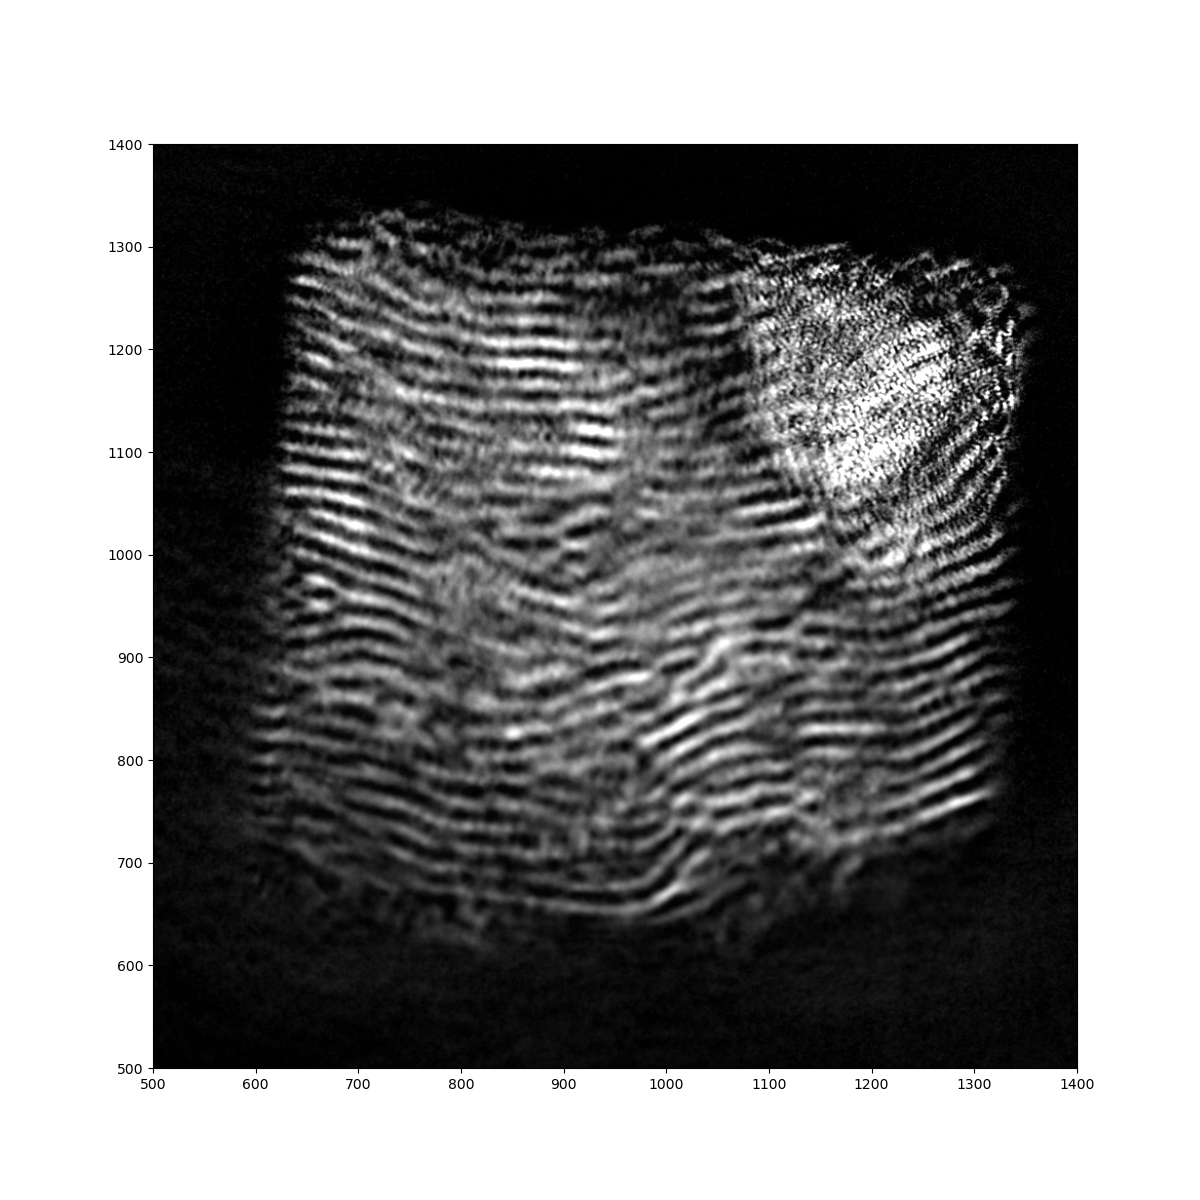

In [13]:
from IPython.display import clear_output
import time
import numpy as np
base_path = r"/dls/e02/data/2026/mg44468-1/processing/batch_ptycho/ptycho_batch_2/20260128_171940/ptyrex/"

out_loc = f"{base_path}28102204_error.err"
output_path = glob.glob(base_path+'*.hdf')[0]
slice_num = 0
loadedin = True
while loadedin:
    # with open(out_loc, 'r') as f:
    #     output = f.readlines()[-1]
    #     print(output)
    
    # if 'PIE reconstruction complete' in output:
    if True:
        with h5py.File(output_path,'r') as f:
            result = f['entry_1/process_1/output_1/object_phase'][()]
            loadedin = False
        fig, ax = plt.subplots(figsize=(12, 12))
        ax.imshow(result[0][slice_num][0][0][0][:][:], cmap='gray',vmin = 0, vmax = result[0][0][0][0][0][:][:].max()/2)
        # ax.imshow(np.rot90(result[0][slice_num][0][0][0][:][:]), cmap='gray',vmin = 0, vmax = result[0][0][0][0][0][:][:].max()/2)

        ax.set_xlim(500,1400)
        ax.set_ylim(500,1400)
        # plt.savefig(f"{base_path}ptycho_{slice_num}.png")
    loadedin=False
    time.sleep(0.1)

In [30]:
result[0][2][0][0][0][:][:].shape

(1919, 1919)

In [ ]:
from IPython.display import clear_output
import time
base_path = r"/dls/e02/data/2026/mg44468-1/processing/batch_ptycho/ptycho_batch_1/20260128_171503/ptyrex/"
out_loc = f"{base_path}28100545_error.err"
output_path = f"{base_path}PtCo_-132ADef_p22m_0_0_20260305-091828.hdf"

slice_num = 0
loadedin = True
while loadedin:
    with open(out_loc, 'r') as f:
        output = f.readlines()[-1]
        print(output)
    
    if 'PIE reconstruction complete' in output:
        with h5py.File(output_path,'r') as f:
            result = f['entry_1/process_1/output_1/object_phase'][()]
            loadedin = False
        fig, ax = plt.subplots(figsize=(12, 12))
        ax.imshow(result[0][slice_num][0][0][0][:][:], cmap='gray',vmin = 0, vmax = result[0][0][0][0][0][:][:].max()/2)
        ax.set_xlim(500,1400)
        ax.set_ylim(500,1400)
        plt.savefig(f"{base_path}ptycho_{slice_num}.png")
    time.sleep(0.1)

In [ ]:
# from datetime import datetime
# timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
# output_json_name = f"{sample_name}_{defocus_A}ADef_{def_val:.2f}m_{timestamp}"
# if def_val < 1:
#     output_json_name = output_json_name.replace('0.','p')
# else:
#     output_json_name = output_json_name.replace('.','p')
# output_json_name = output_json_name + '.json'
# print(output_json_name)

PtCo_68ADef_p22m_20260304-204931.json


In [ ]:
# old:
# chosen_datasets = json.load(open('selected_datasets_complete.json', 'r'))
# log_dir = os.path.join(out_dir, f'logs_ptyrex')
# os.makedirs(log_dir, exist_ok=True)


# prepared_datasets = []
# initial_job = True
# jobs_submitted = 0
# concurrent_jobs = 5
# batch_size = 40
# # Now loops through datasets and creates subfolder for each dataset
# for num, dataset in enumerate(chosen_datasets):
#     dataset_name = dataset.get('folder')
#     crop_coords = dataset.get('coords')

#     out_dir_data = os.path.join(out_dir, dataset_name).replace('\\', '/')
#     # if os.exists(out_dir_data):
#     #     continue # skip if already existing dir
#     os.makedirs(out_dir_data, exist_ok=True) 

#     defocus_A = get_parallax_defocus(
#         root_path=root_path, 
#         out_dir=out_dir_data, 
#         manual_meta={
#             'folder': dataset_name,
#             'coords': crop_coords
#         }, 
#         step_size=step_size, 
#         mrad_per_pix=mrad_per_pix, 
#         ht_ev=ht_ev, 
#         save_fig=True
#     )
#     print(defocus_A)
#     copy_virtual_bf_image(
#         root_path=root_path, 
#         out_dir=out_dir_data, 
#         dataset_name=dataset_name
#     )

#     prepared_datasets.append(
#         {
#             'sample_details' : {
#                 'sample_name': sample_name,
#                 'defocus': defocus_A, # in angstroms
#                 'def_val': def_val,
#                 'dataset_name': dataset_name,
#             },
#             'out_dir_data' : out_dir_data,

#         }
#     )

#     if initial_job and len(prepared_datasets) == concurrent_jobs:
#         print(f"Creating initial ptycho job for first {concurrent_jobs} datasets ...")

#         submit_json_paths = []
#         submit_output_dirs = []
#         for d in prepared_datasets:
#             json_path = create_experiment_ptycho_config(
#                 out_dir_data=d['out_dir_data'], 
#                 base_json_path=base_json_path, 
#                 sample_details=d['sample_details']
#             )
#             submit_json_paths.append(json_path)
#             submit_output_dirs.append(d['out_dir_data'])

#         create_ptycho_job_multi(
#             json_paths=submit_json_paths,
#             output_dirs=submit_output_dirs,
#             log_dir=log_dir,
#             concurrent_jobs=concurrent_jobs
#         )
#         initial_job = False
#         jobs_submitted += len(prepared_datasets)
#         prepared_datasets = [] # reset prepared datasets after submitting job

#     elif initial_job:
#         continue # keep preparing datasets until we have enough to submit the first job

#     else:
#         if len(prepared_datasets) == batch_size or num == len(chosen_datasets) - 1: # submit next batch or remaining datasets in the last batch
#             print(f"Submitting next batch of {len(prepared_datasets)} datasets ...")

#             submit_json_paths = []
#             submit_output_dirs = []
#             for d in prepared_datasets:
#                 json_path = create_experiment_ptycho_config(
#                     out_dir_data=d['out_dir_data'], 
#                     base_json_path=base_json_path, 
#                     sample_details=d['sample_details']
#                 )
#                 submit_json_paths.append(json_path)
#                 submit_output_dirs.append(d['out_dir_data'])

#             create_ptycho_job_multi(
#                 json_paths=submit_json_paths,
#                 output_dirs=submit_output_dirs,
#                 log_dir=log_dir,
#                 concurrent_jobs=concurrent_jobs
#             )
#             jobs_submitted += len(prepared_datasets)
#             prepared_datasets = [] # reset prepared datasets after submitting job

#         else:
#             continue # keep preparing datasets until we have enough for the next batch or at end